In [ ]:
pip install arch


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from statsmodels.tsa.arima.model import ARIMA
from arch import arch_model
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Conv1D, Flatten
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Load the CSV file
data = pd.read_csv('ETF_prices.csv')

<ipython-input-8-30dfb6ab7ef8>:2: DtypeWarning: Columns (0,1) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv('ETF_prices.csv')


In [ ]:
# Data Preparation
# Convert 'price_date' to datetime
data['price_date'] = pd.to_datetime(data['price_date'])

In [ ]:
# Check for missing values and impute
data.fillna(method='ffill', inplace=True)

<ipython-input-10-bafed24bd17a>:2: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data.fillna(method='ffill', inplace=True)


In [ ]:
# Normalize numerical columns
scaler = MinMaxScaler()
data[['open', 'high', 'low', 'close', 'adj_close', 'volume']] = scaler.fit_transform(
    data[['open', 'high', 'low', 'close', 'adj_close', 'volume']]
)

In [ ]:
# Encode categorical columns if necessary
encoder = LabelEncoder()
data['fund_symbol'] = encoder.fit_transform(data['fund_symbol'])

In [ ]:
# Create time-series sequences for deep learning models
def create_sequences(data, target_column, seq_length):
    sequences = []
    targets = []
    for i in range(len(data) - seq_length):
        seq = data[i:i + seq_length]
        label = target_column[i + seq_length]
        sequences.append(seq)
        targets.append(label)
    return np.array(sequences), np.array(targets)

seq_length = 10
features = ['open', 'high', 'low', 'close', 'adj_close', 'volume']
X, y = create_sequences(data[features].values, data['close'].values, seq_length)

In [ ]:
# Split into train, validation, and test sets
train_size = int(0.7 * len(X))
val_size = int(0.15 * len(X))
X_train, X_val, X_test = X[:train_size], X[train_size:train_size + val_size], X[train_size + val_size:]
y_train, y_val, y_test = y[:train_size], y[train_size:train_size + val_size], y[train_size + val_size:]

In [ ]:
# ARIMA Model
arima_model = ARIMA(data['close'], order=(1, 1, 1))
arima_result = arima_model.fit()
print(arima_result.summary())

                               SARIMAX Results                                
Dep. Variable:                  close   No. Observations:              1048575
Model:                 ARIMA(1, 1, 1)   Log Likelihood             6076011.406
Date:                Mon, 30 Dec 2024   AIC                      -12152016.811
Time:                        13:33:16   BIC                      -12151981.222
Sample:                             0   HQIC                     -12152007.036
                            - 1048575                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.2816   1.02e-05  -2.77e+04      0.000      -0.282      -0.282
ma.L1          0.3524   1.02e-05   3.45e+04      0.000       0.352       0.352
sigma2      5.424e-07    4.9e-12   1.11e+05      0.0

In [ ]:
# GARCH Model
garch_model = arch_model(data['close'], vol='Garch', p=1, q=1)
garch_result = garch_model.fit()
print(garch_result.summary())

/usr/local/lib/python3.10/dist-packages/arch/univariate/base.py:309: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 0.0001933. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 100 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  warnings.warn(


Iteration:      1,   Func. Count:      5,   Neg. LLF: -4520477.942638949
Inequality constraints incompatible    (Exit mode 4)
            Current function value: -4520477.972023976
            Iterations: 1
            Function evaluations: 5
            Gradient evaluations: 1


/usr/local/lib/python3.10/dist-packages/arch/univariate/base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(


                     Constant Mean - GARCH Model Results                      
Dep. Variable:                  close   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:            4.52048e+06
Distribution:                  Normal   AIC:                      -9.04095e+06
Method:            Maximum Likelihood   BIC:                      -9.04090e+06
                                        No. Observations:              1048575
Date:                Mon, Dec 30 2024   Df Residuals:                  1048574
Time:                        13:45:59   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
mu             0.0418  9.076e-09  4.608e+06      0.000 [4.

In [ ]:
# LSTM Model
lstm_model = Sequential([
    LSTM(50, return_sequences=True, input_shape=(seq_length, len(features))),
    LSTM(50),
    Dense(1)
])
lstm_model.compile(optimizer='adam', loss='mse')
lstm_model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=20, batch_size=32)

/usr/local/lib/python3.10/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
9829/9829 ━━━━━━━━━━━━━━━━━━━━ 137s 14ms/step - loss: 2.0172e-05 - val_loss: 1.7776e-08
Epoch 2/20
9829/9829 ━━━━━━━━━━━━━━━━━━━━ 143s 14ms/step - loss: 4.7652e-06 - val_loss: 1.2836e-06
Epoch 3/20
9829/9829 ━━━━━━━━━━━━━━━━━━━━ 141s 14ms/step - loss: 3.9465e-06 - val_loss: 1.1363e-06
Epoch 4/20
9829/9829 ━━━━━━━━━━━━━━━━━━━━ 138s 13ms/step - loss: 3.7069e-06 - val_loss: 3.2710e-08
Epoch 5/20
9829/9829 ━━━━━━━━━━━━━━━━━━━━ 149s 14ms/step - loss: 2.5934e-06 - val_loss: 8.7177e-08
Epoch 6/20
9829/9829 ━━━━━━━━━━━━━━━━━━━━ 131s 13ms/step - loss: 3.3622e-06 - val_loss: 1.8601e-08
Epoch 7/20
9829/9829 ━━━━━━━━━━━━━━━━━━━━ 125s 13ms/step - loss: 3.3714e-06 - val_loss: 7.8870e-11
Epoch 8/20
9829/9829 ━━━━━━━━━━━━━━━━━━━━ 140s 13ms/step - loss: 3.0677e-06 - val_loss: 4.8826e-07
Epoch 9/20
9829/9829 ━━━━━━━━━━━━━━━━━━━━ 144s 13ms/step - loss: 3.0004e-06 - val_loss: 1.7806e-08
Epoch 10/20
9829/9829 ━━━━━━━━━━━━━━━━━━━━ 146s 13ms/step - loss: 2.1690e-06 - val_loss: 1.3347e-07
Epoch 11/

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━

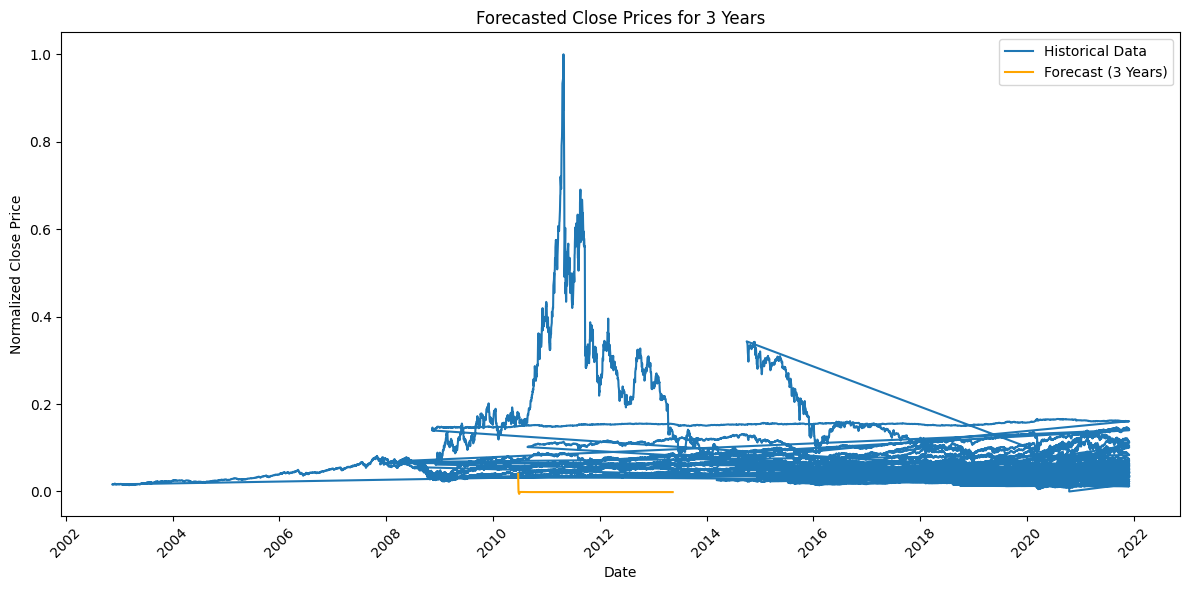

In [ ]:
# Function to forecast future values
def forecast_future(model, data, seq_length, num_days, features):
    # Initialize the last sequence from the data
    current_sequence = data[-seq_length:, :].reshape(1, seq_length, len(features))
    future_predictions = []

    # Iteratively predict the next value
    for _ in range(num_days):
        # Predict the next value
        next_value = model.predict(current_sequence)[0, 0]
        future_predictions.append(next_value)

        # Update the sequence by appending the predicted value
        next_row = np.zeros((1, len(features)))
        next_row[0, 3] = next_value  # Assuming 'close' is at index 3 in the features
        current_sequence = np.append(current_sequence[:, 1:, :], next_row.reshape(1, 1, len(features)), axis=1)

    return future_predictions

# Forecasting parameters
num_days = 3 * 252  # 3 years of trading days
forecasted_values = forecast_future(lstm_model, data[features].values, seq_length, num_days, features)

# Create date range for the forecast
last_date = pd.Timestamp('2020-12-31')
last_date = data['price_date'].iloc[-1]
forecast_dates = pd.date_range(start=last_date, periods=num_days + 1, freq='B')[1:]  # 'B' for business days

# Plot the historical and forecasted values with dates
plt.figure(figsize=(12, 6))
plt.plot(data['price_date'], data['close'], label='Historical Data')
plt.plot(forecast_dates, forecasted_values, label='Forecast (3 Years)', color='orange')
plt.legend()
plt.title('Forecasted Close Prices for 3 Years')
plt.xlabel('Date')
plt.ylabel('Normalized Close Price')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# CNN Model
cnn_model = Sequential([
    Conv1D(64, kernel_size=3, activation='relu', input_shape=(seq_length, len(features))),
    Flatten(),
    Dense(1)
])
cnn_model.compile(optimizer='adam', loss='mse')
cnn_model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=20, batch_size=32)

/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
22938/22938 ━━━━━━━━━━━━━━━━━━━━ 43s 2ms/step - loss: 7.1230e-06 - val_loss: 3.7607e-08
Epoch 2/20
22938/22938 ━━━━━━━━━━━━━━━━━━━━ 83s 2ms/step - loss: 2.4848e-06 - val_loss: 3.0604e-08
Epoch 3/20
22938/22938 ━━━━━━━━━━━━━━━━━━━━ 42s 2ms/step - loss: 2.2947e-06 - val_loss: 6.4997e-08
Epoch 4/20
22938/22938 ━━━━━━━━━━━━━━━━━━━━ 83s 2ms/step - loss: 1.7090e-06 - val_loss: 6.5443e-09
Epoch 5/20
22938/22938 ━━━━━━━━━━━━━━━━━━━━ 81s 2ms/step - loss: 1.9864e-06 - val_loss: 4.9445e-10
Epoch 6/20
22938/22938 ━━━━━━━━━━━━━━━━━━━━ 82s 2ms/step - loss: 2.3647e-06 - val_loss: 1.7098e-11
Epoch 7/20
22938/22938 ━━━━━━━━━━━━━━━━━━━━ 42s 2ms/step - loss: 1.7060e-06 - val_loss: 2.3330e-06
Epoch 8/20
22938/22938 ━━━━━━━━━━━━━━━━━━━━ 42s 2ms/step - loss: 2.5426e-06 - val_loss: 1.8634e-08
Epoch 9/20
22938/22938 ━━━━━━━━━━━━━━━━━━━━ 82s 2ms/step - loss: 1.4500e-06 - val_loss: 1.7826e-08
Epoch 10/20
22938/22938 ━━━━━━━━━━━━━━━━━━━━ 43s 2ms/step - loss: 1.5229e-06 - val_loss: 3.3211e-10
Epoch 11/

In [ ]:
# Model Evaluation
def evaluate_model(model, X_test, y_test):
    predictions = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    mae = mean_absolute_error(y_test, predictions)
    return rmse, mae

lstm_rmse, lstm_mae = evaluate_model(lstm_model, X_test, y_test)
cnn_rmse, cnn_mae = evaluate_model(cnn_model, X_test, y_test)

print(f"LSTM RMSE: {lstm_rmse}, MAE: {lstm_mae}")
print(f"CNN RMSE: {cnn_rmse}, MAE: {cnn_mae}")

4916/4916 ━━━━━━━━━━━━━━━━━━━━ 20s 4ms/step
4916/4916 ━━━━━━━━━━━━━━━━━━━━ 6s 1ms/step
LSTM RMSE: 9.913669538165483e-05, MAE: 9.913669537755379e-05
CNN RMSE: 0.001579114267481897, MAE: 0.0015791142674818973


4916/4916 ━━━━━━━━━━━━━━━━━━━━ 21s 4ms/step
4916/4916 ━━━━━━━━━━━━━━━━━━━━ 6s 1ms/step


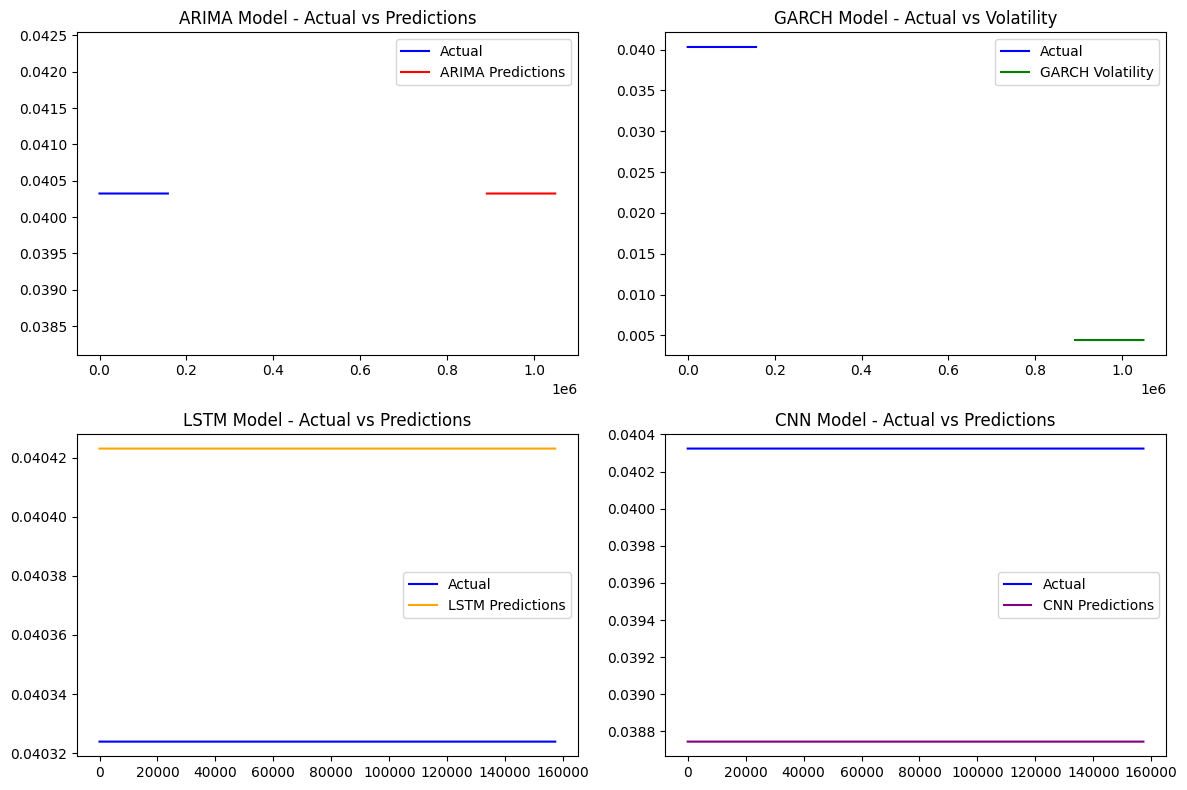

In [ ]:
# ARIMA Predictions
arima_predictions = arima_result.predict(start=len(data) - len(y_test), end=len(data) - 1, typ='levels')

# GARCH Predictions (GARCH model is typically used for volatility prediction, so here we can use the predicted values)
garch_predictions = garch_result.conditional_volatility[-len(y_test):]  # Using volatility for plotting

# LSTM Predictions
lstm_predictions = lstm_model.predict(X_test)

# CNN Predictions
cnn_predictions = cnn_model.predict(X_test)

# Plotting
plt.figure(figsize=(12, 8))

# Plot Actual vs ARIMA Predictions
plt.subplot(2, 2, 1)
plt.plot(y_test, label='Actual', color='blue')
plt.plot(arima_predictions, label='ARIMA Predictions', color='red')
plt.title('ARIMA Model - Actual vs Predictions')
plt.legend()

# Plot Actual vs GARCH Predictions (Volatility)
plt.subplot(2, 2, 2)
plt.plot(y_test, label='Actual', color='blue')
plt.plot(garch_predictions, label='GARCH Volatility', color='green')
plt.title('GARCH Model - Actual vs Volatility')
plt.legend()

# Plot Actual vs LSTM Predictions
plt.subplot(2, 2, 3)
plt.plot(y_test, label='Actual', color='blue')
plt.plot(lstm_predictions, label='LSTM Predictions', color='orange')
plt.title('LSTM Model - Actual vs Predictions')
plt.legend()

# Plot Actual vs CNN Predictions
plt.subplot(2, 2, 4)
plt.plot(y_test, label='Actual', color='blue')
plt.plot(cnn_predictions, label='CNN Predictions', color='purple')
plt.title('CNN Model - Actual vs Predictions')
plt.legend()

# Show the plots
plt.tight_layout()
plt.show()

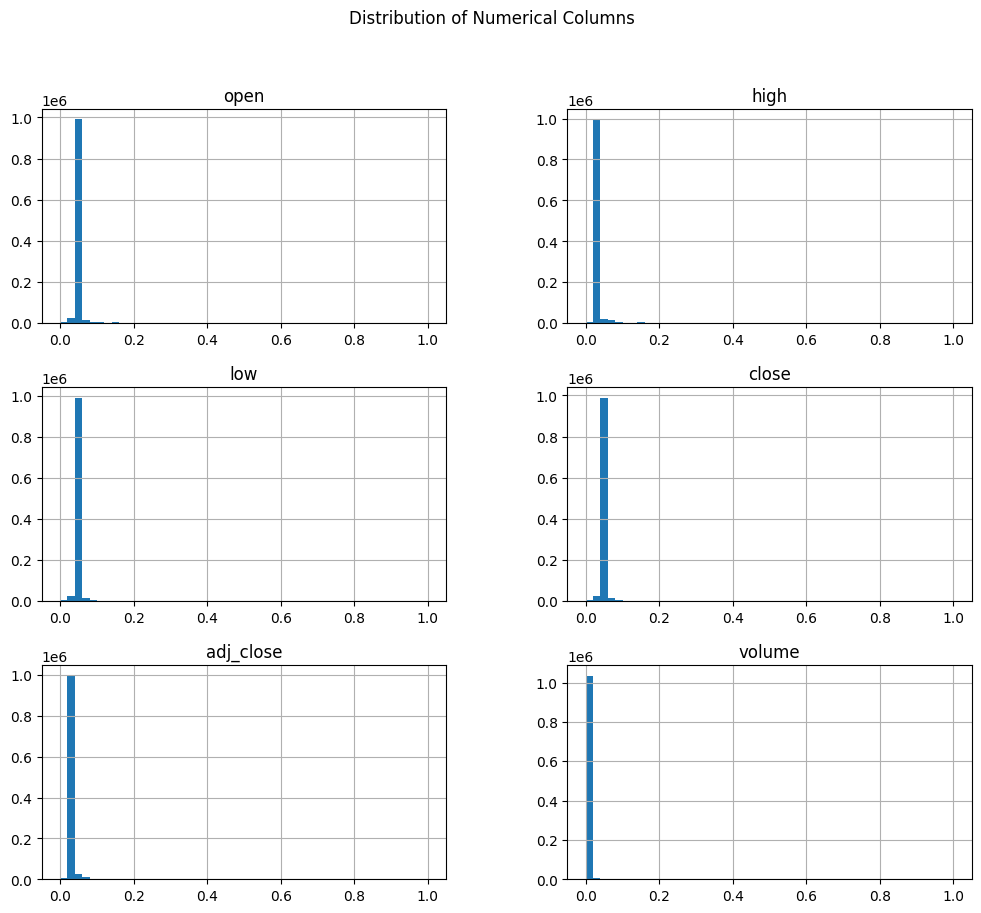

In [ ]:
# Plot the distribution of numerical columns
numerical_columns = ['open', 'high', 'low', 'close', 'adj_close', 'volume']
data[numerical_columns].hist(figsize=(12, 10), bins=50)
plt.suptitle('Distribution of Numerical Columns')
plt.show()


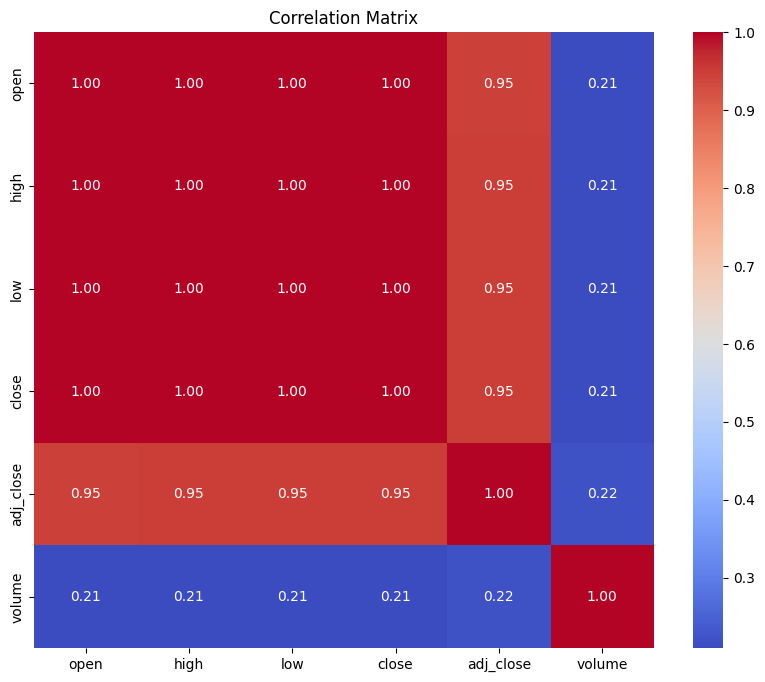

In [ ]:
# Plot the correlation matrix to understand relationships between variables
correlation_matrix = data[numerical_columns].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()
